# Taller 1: Teoría de Aprendizaje de Máquina

Este notebook contiene la solución e interpretación analítica de los puntos computacionales del Taller 1.

## SECCIÓN 1: FRONTERA LINEAL Y ACTUALIZACIÓN DEL PERCEPTRÓN

En esta sección se evalúan puntos sobre una frontera de decisión lineal definida inicialmente y se simula paso a paso el algoritmo de actualización del Perceptrón ante un error de clasificación.

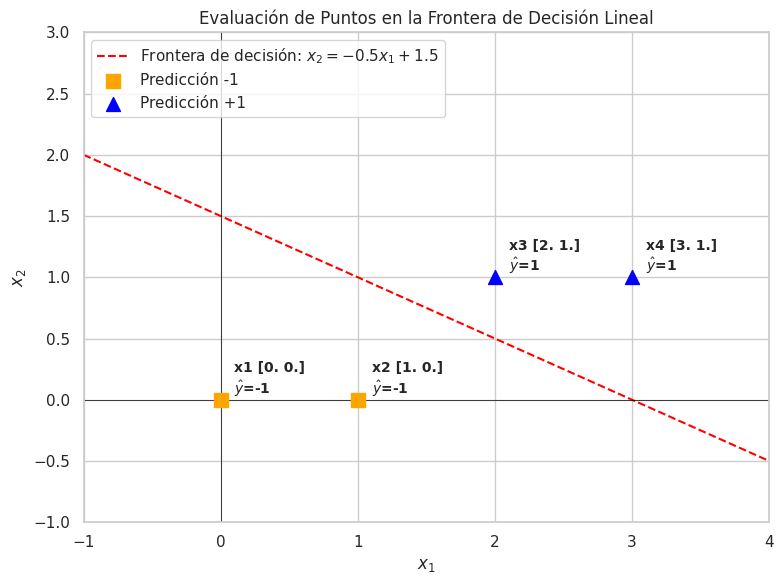

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Fijar estilo de gráficos
sns.set_theme(style="whitegrid")
np.random.seed(42)

# --- 1.1 Graficar frontera de decisión inicial ---
w = np.array([1.0, 2.0])
b = -3.0
points = np.array([[0.0, 0.0], [1.0, 0.0], [2.0, 1.0], [3.0, 1.0]])
point_labels = ['x1', 'x2', 'x3', 'x4']

# Evaluar predicciones: y_hat = 1 si w^T*x + b > 0 de lo contrario -1
predictions = []
for x in points:
    val = np.dot(w, x) + b
    pred = 1 if val > 0 else -1
    predictions.append(pred)

# Definir el rango para graficar la recta w^T*x + b = 0 => x2 = -0.5*x1 + 1.5
x1_vals = np.linspace(-1, 4, 100)
x2_vals = -0.5 * x1_vals + 1.5

plt.figure(figsize=(8, 6))
plt.plot(x1_vals, x2_vals, label=r'Frontera de decisión: $x_2 = -0.5x_1 + 1.5$', color='red', linestyle='--')

# Graficar puntos evaluados
for i, (point, pred) in enumerate(zip(points, predictions)):
    color = 'blue' if pred == 1 else 'orange'
    marker = '^' if pred == 1 else 's'
    plt.scatter(point[0], point[1], color=color, marker=marker, s=100, zorder=5,
                label=f'Predicción +1' if (pred == 1 and i==2) else (f'Predicción -1' if (pred == -1 and i==0) else ""))
    plt.text(point[0] + 0.1, point[1] + 0.05, f"{point_labels[i]} {point}\n$\\hat{{y}}$={pred}", fontsize=10, weight='bold')

plt.xlim(-1, 4)
plt.ylim(-1, 3)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.title('Evaluación de Puntos en la Frontera de Decisión Lineal')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

In [2]:
# --- 1.3 Ejercicio de actualización del Perceptrón ---
w_init = np.array([0.0, 0.0])
b_init = 0.0
eta = 0.5
x_train = np.array([2.0, 1.0])
y_true = 1

print("=== Actualización del Perceptrón (Punto 1.3) ===")
# 1. Evaluar si está mal clasificado
score_init = np.dot(w_init, x_train) + b_init
y_hat_init = 1 if score_init > 0 else -1 # Usando regla convencional para w^T*x + b <= 0 -> -1

print(f"Parámetros iniciales: w = {w_init}, b = {b_init}")
print(f"Punto de entrenamiento: x = {x_train}, etiqueta real y = {y_true}")
print(f"Score obtenido: {score_init} -> Predicción y_hat = {y_hat_init}")

is_misclassified = (y_hat_init != y_true) or (score_init <= 0)
print(f"¿Está mal clasificado?: {is_misclassified}")

# 2. Calcular margen funcional inicial
margen_init = y_true * (np.dot(w_init, x_train) + b_init)
print(f"Margen funcional inicial: {margen_init}")

# 3. Aplicar regla de actualización
if is_misclassified:
    w_new = w_init + eta * y_true * x_train
    b_new = b_init + eta * y_true
    print(f"\n--- Actualizando parámetros con eta = {eta} ---")
    print(f"w_nuevo = {w_new}")
    print(f"b_nuevo = {b_new}")

    # 4. Calcular margen funcional nuevo y verificación analítica
    margen_new = y_true * (np.dot(w_new, x_train) + b_new)
    print(f"Margen funcional nuevo: {margen_new}")
    print(f"Incremento del margen: {margen_new - margen_init} (Verificado analíticamente)")

=== Actualización del Perceptrón (Punto 1.3) ===
Parámetros iniciales: w = [0. 0.], b = 0.0
Punto de entrenamiento: x = [2. 1.], etiqueta real y = 1
Score obtenido: 0.0 -> Predicción y_hat = -1
¿Está mal clasificado?: True
Margen funcional inicial: 0.0

--- Actualizando parámetros con eta = 0.5 ---
w_nuevo = [1.  0.5]
b_nuevo = 0.5
Margen funcional nuevo: 3.0
Incremento del margen: 3.0 (Verificado analíticamente)


## SECCIÓN 2: IMPLEMENTACIÓN DE KNN MANUAL

Implementación nativa (scratch) del algoritmo K-Vecinos Cercanos para clasificar un punto de consulta $q$ a partir de la distancia Euclidiana exacta.

In [3]:
def knn_manual(train_data, train_labels, query_point, k_values):
    """
    Implementación manual de KNN para clasificar un punto de consulta q.
    """
    # 1. Calcular distancia euclidiana exacta
    distances = []
    for idx, x_i in enumerate(train_data):
        dist = np.sqrt(np.sum((np.array(x_i) - np.array(query_point))**2))
        distances.append((idx, dist, train_labels[idx]))

    # 2. Ordenar las distancias de menor a mayor
    distances_sorted = sorted(distances, key=lambda val: val[1])

    # Imprimir tabla detallada de distancias y vecinos
    print(f"Tabla de distancias al punto de consulta q = {query_point}:")
    print(f"{'Vecino':<10} | {'Coordenadas':<12} | {'Distancia Exacta':<18} | {'Clase':<5}")
    print("-" * 55)
    for i, (idx, dist, label) in enumerate(distances_sorted):
        coord_str = str(tuple(train_data[idx]))
        print(f"x_{idx+1:<7} | {coord_str:<12} | {dist:<18.4f} | {label:<5}")
    print("\n")

    # 3. Determinar predicciones por votación mayoritaria para cada K
    for k in k_values:
        k_neighbors = distances_sorted[:k]
        classes = [neighbor[2] for neighbor in k_neighbors]

        # Contar clases
        class_counts = {}
        for cls in classes:
            class_counts[cls] = class_counts.get(cls, 0) + 1

        # Elegir clase mayoritaria
        pred_class = max(class_counts, key=class_counts.get)
        print(f"Para K = {k}: Vecinos seleccionados -> {[f'x_{item[0]+1}' for item in k_neighbors]}")
        print(f"Votos: {class_counts} -> Clase Asignada: {pred_class}\n")

# Datos del problema
X_train_knn = np.array([[0.0, 0.0], [1.0, 0.0], [3.0, 1.0], [0.0, 3.0], [1.1, 1.1]])
y_train_knn = ['A', 'A', 'B', 'B', 'B']
q = [1.0, 1.0]

knn_manual(X_train_knn, y_train_knn, q, k_values=[1, 3, 5])

Tabla de distancias al punto de consulta q = [1.0, 1.0]:
Vecino     | Coordenadas  | Distancia Exacta   | Clase
-------------------------------------------------------
x_5       | (np.float64(1.1), np.float64(1.1)) | 0.1414             | B    
x_2       | (np.float64(1.0), np.float64(0.0)) | 1.0000             | A    
x_1       | (np.float64(0.0), np.float64(0.0)) | 1.4142             | A    
x_3       | (np.float64(3.0), np.float64(1.0)) | 2.0000             | B    
x_4       | (np.float64(0.0), np.float64(3.0)) | 2.2361             | B    


Para K = 1: Vecinos seleccionados -> ['x_5']
Votos: {'B': 1} -> Clase Asignada: B

Para K = 3: Vecinos seleccionados -> ['x_5', 'x_2', 'x_1']
Votos: {'B': 1, 'A': 2} -> Clase Asignada: A

Para K = 5: Vecinos seleccionados -> ['x_5', 'x_2', 'x_1', 'x_3', 'x_4']
Votos: {'B': 3, 'A': 2} -> Clase Asignada: B



## SECCIÓN 3: KNN EXPERIMENTAL CON SCIKIT-LEARN (`make_moons`)

Evaluación empírica del algoritmo KNN utilizando datos sintéticos no lineales con ruido y análisis del compromiso sesgo-varianza.

In [4]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. Generación de datos
X_moons, y_moons = make_moons(n_samples=300, noise=0.20, random_state=42)

# 2. Partición Estratificada (70/30)
X_train, X_test, y_train, y_test = train_test_split(
    X_moons, y_moons, test_size=0.30, random_state=42, stratify=y_moons
)

# 3. Entrenamiento y Evaluación
k_list = [1, 5, 15]
classifiers = {}

print("=== Desempeño del Clasificador KNN en make_moons ===")
for k in k_list:
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_train, y_train)
    classifiers[k] = clf

    acc_train = accuracy_score(y_train, clf.predict(X_train))
    acc_test = accuracy_score(y_test, clf.predict(X_test))
    print(f"K = {k:02d} | Exactitud Entrenamiento: {acc_train:.4f} | Exactitud Prueba: {acc_test:.4f}")

=== Desempeño del Clasificador KNN en make_moons ===
K = 01 | Exactitud Entrenamiento: 1.0000 | Exactitud Prueba: 0.9333
K = 05 | Exactitud Entrenamiento: 0.9571 | Exactitud Prueba: 0.9556
K = 15 | Exactitud Entrenamiento: 0.9571 | Exactitud Prueba: 0.9333


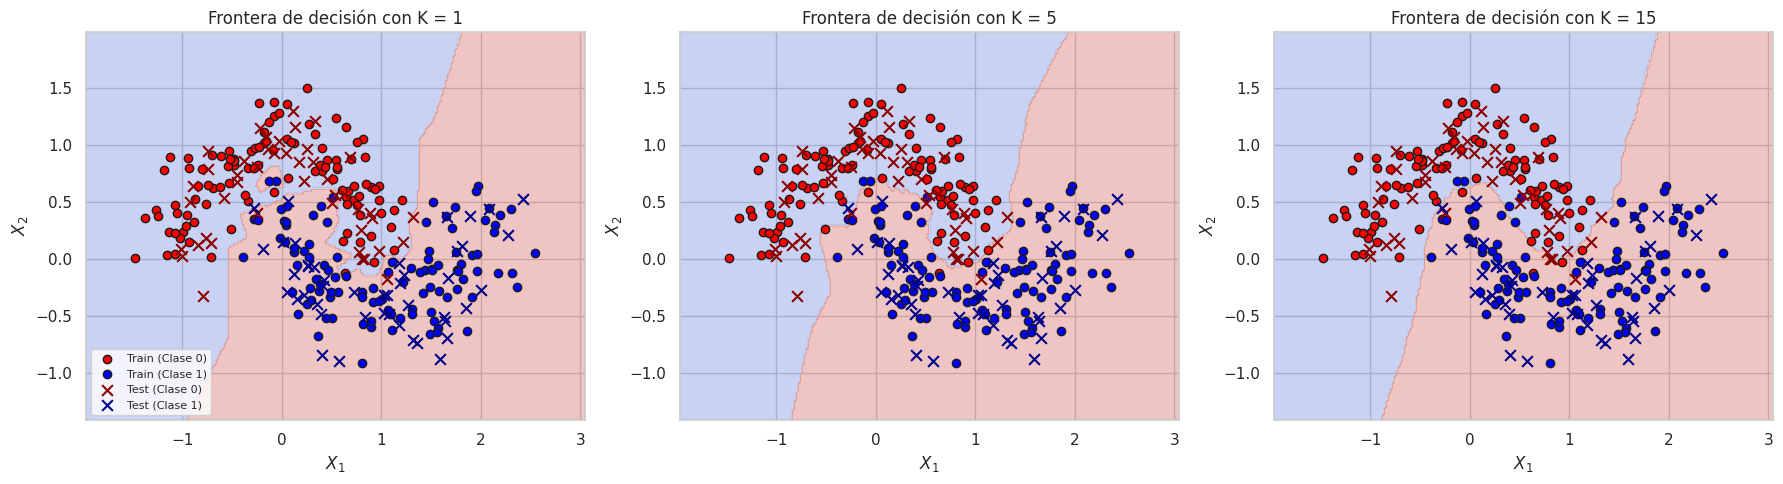

In [5]:
# 4. Visualización de regiones de decisión
x_min, x_max = X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5
y_min, y_max = X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, k in zip(axes, k_list):
    clf = classifiers[k]
    # Predecir sobre el meshgrid
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Graficar la región de decisión coloreada
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')

    # Graficar datos de entrenamiento
    ax.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1], color='red', marker='o', label='Train (Clase 0)', edgecolors='k')
    ax.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], color='blue', marker='o', label='Train (Clase 1)', edgecolors='k')

    # Graficar datos de prueba
    ax.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], color='darkred', marker='x', s=60, label='Test (Clase 0)')
    ax.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], color='darkblue', marker='x', s=60, label='Test (Clase 1)')

    ax.set_title(f'Frontera de decisión con K = {k}')
    ax.set_xlabel('$X_1$')
    ax.set_ylabel('$X_2$')
    if k == 1:
        ax.legend(loc='lower left', prop={'size': 8})

plt.tight_layout()
plt.show()

### Análisis y Discusión (Compromiso Sesgo-Varianza)

* **¿Qué ocurre con $k=1$?**
  - Presenta **alta varianza y bajo sesgo**. La exactitud en entrenamiento es perfecta (1.0000) porque el modelo simplemente "memoriza" cada punto del conjunto. Sin embargo, la frontera de decisión es muy compleja, irregular y susceptible al ruido (se aprecian islas e imperfecciones), lo que reduce el rendimiento de generalización en el set de prueba.
* **¿Qué ocurre con $k=15$?**
  - Presenta **alto sesgo y baja varianza**. La frontera se suaviza drásticamente. Al considerar un número tan alto de vecinos se reducen las complejidades locales, pero corremos el riesgo de omitir patrones y subajustar el dataset en regiones altamente no lineales.
* **Mejor Generalización y Selección de Hiperparámetros**:
  - Generalmente un punto intermedio (como $k=5$) presenta el mejor balance de generalización. El ajuste de hiperparámetros (elección de $k$) debe hacerse mediante **Validación Cruzada (Cross-Validation)** y no con el conjunto de test para evitar el sesgo de optimismo, asegurando que el conjunto de prueba se mantenga completamente libre para una estimación final no sesgada del error real del sistema.

## SECCIÓN 4: EVALUACIÓN DE UN CLASIFICADOR BINARIO

En esta sección calculamos métricas de rendimiento clásicas a partir de las predicciones de un modelo.

In [6]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# 1. Datos
y_true_bin = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
y_pred_bin = np.array([0, 1, 0, 0, 1, 0, 1, 1, 0, 1])

# 2. Cálculo manual programado mediante operaciones booleanas
TP = np.sum((y_true_bin == 1) & (y_pred_bin == 1))
TN = np.sum((y_true_bin == 0) & (y_pred_bin == 0))
FP = np.sum((y_true_bin == 0) & (y_pred_bin == 1))
FN = np.sum((y_true_bin == 1) & (y_pred_bin == 0))

accuracy = (TP + TN) / len(y_true_bin)
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * (precision * recall) / (precision + recall)

print("=== Cálculo Manual (Vía Operaciones Booleanas) ===")
print(f"Verdaderos Positivos (TP): {TP}")
print(f"Verdaderos Negativos (TN): {TN}")
print(f"Falsos Positivos (FP): {FP}")
print(f"Falsos Negativos (FN): {FN}")
print(f"Accuracy  = {accuracy:.4f}")
print(f"Precision = {precision:.4f}")
print(f"Recall    = {recall:.4f}")
print(f"F1-Score  = {f1:.4f}\n")

# 3. Verificación con Scikit-learn
print("=== Verificación con Scikit-Learn ===")
conf_matrix = confusion_matrix(y_true_bin, y_pred_bin)
print(f"Accuracy (sklearn):  {accuracy_score(y_true_bin, y_pred_bin):.4f}")
print(f"Precision (sklearn): {precision_score(y_true_bin, y_pred_bin):.4f}")
print(f"Recall (sklearn):    {recall_score(y_true_bin, y_pred_bin):.4f}")
print(f"F1-Score (sklearn):  {f1_score(y_true_bin, y_pred_bin):.4f}")

=== Cálculo Manual (Vía Operaciones Booleanas) ===
Verdaderos Positivos (TP): 4
Verdaderos Negativos (TN): 3
Falsos Positivos (FP): 1
Falsos Negativos (FN): 2
Accuracy  = 0.7000
Precision = 0.8000
Recall    = 0.6667
F1-Score  = 0.7273

=== Verificación con Scikit-Learn ===
Accuracy (sklearn):  0.7000
Precision (sklearn): 0.8000
Recall (sklearn):    0.6667
F1-Score (sklearn):  0.7273


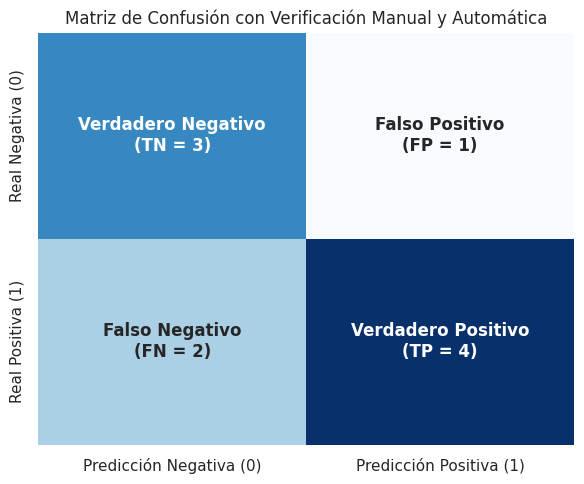

In [7]:
# 4. Graficar Matriz de Confusión
plt.figure(figsize=(6, 5))
labels = [
    [f'Verdadero Negativo\n(TN = {TN})', f'Falso Positivo\n(FP = {FP})'],
    [f'Falso Negativo\n(FN = {FN})', f'Verdadero Positivo\n(TP = {TP})']
]

sns.heatmap(conf_matrix, annot=labels, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Predicción Negativa (0)', 'Predicción Positiva (1)'],
            yticklabels=['Real Negativa (0)', 'Real Positiva (1)'],
            annot_kws={"size": 12, "weight": "bold"})
plt.title('Matriz de Confusión con Verificación Manual y Automática')
plt.tight_layout()
plt.show()

### Discusión Analítica sobre la Exactitud (Accuracy)

La exactitud o *Accuracy* puede resultar sumamente engañosa en dos casos fundamentales:

1. **Datos fuertemente desbalanceados**:
   - Si un conjunto de datos médicos tiene un 99% de pacientes sanos y 1% de pacientes enfermos, un clasificador trivial que prediga "sano" para todo el mundo obtendrá una exactitud del 99%. Sin embargo, este modelo es completamente inútil ya que falla en detectar al 100% de la población de interés (pacientes enfermos).

2. **Escenarios con costos asimétricos**:
   - En aplicaciones de misión crítica como la medicina (ej. detección de cáncer) o sistemas financieros (ej. detección de fraude), el costo de un **Falso Negativo** (clasificar a un enfermo como sano, privándolo de tratamiento oportuno) es abismalmente más alto que el costo de un **Falso Positivo** (alarmar a un paciente sano, que luego resolverá la duda con exámenes confirmatorios). En este sentido, la métrica **Recall** (sensibilidad) se vuelve primordial y no puede ser explicada eficientemente por un promedio simple como la Exactitud.